# 09 · P4 backtest: when to retrain

Replays weeks 12-26 as if the system were live, with the components tuned in notebooks 06-08:
- **scoring**: tuned LightGBM structure (recency weights, 255 leaves), learning rate 0.1 to keep the replay affordable;
- **decision**: Platt-calibrated probabilities, cost rule capped at 1% of good customers declined (also the 3-action rule);
- **monitoring**: the tuned alarm rules (cached weekly results from notebook 08).

**Timeline.**
- The system launches at week 12 with a model trained on weeks 0-11, whose labels are assumed mature.
- A week-w transaction is labelled at the end of week w + delay.
- A retrain at the end of week t uses labels up to max(11, t − delay), and the new model scores from week t + 1.
- A model never scores a week it was trained or calibrated on (tested in `tests/test_backtest.py`).

**Policies**: never, every 4 weeks, on a drift alarm, and every week (an upper bound on what retraining can give). **Label delays**: 2, 4 and 17 weeks (≈ the 120-day chargeback window).

Pre-registered: **H5**, drift-triggered retraining is no worse than periodic retraining with fewer retrains; **H3**, drift alarms precede performance drops.

In [1]:
import gc
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud.backtest import POLICIES, fit_snapshot, retrain_schedule, simulate
from fraud.config import load_config
from fraud.data import ENTITY_COL, PROCESSED_DIR, TARGET, load_dataset
from fraud.decision import load_costs, paired_cost_diff
from fraud.drift import apply_alarm_rules
from fraud.features import add_past_features, add_row_features, feature_columns

mcfg, model_cfg = load_config("monitoring"), load_config("model")
rcfg = mcfg["retraining"]
costs = load_costs()
CAP = costs["constraints"]["max_good_decline_rate"]
LAUNCH, DELAYS, PERIOD, RETRAIN_COST = rcfg["launch_week"], rcfg["label_delays_weeks"], rcfg["period_weeks"], rcfg["retrain_cost"]
WEEKS = list(range(LAUNCH, 27))
FIG_DIR, SNAP_DIR = Path("../reports/figures"), PROCESSED_DIR / "backtest_snapshots"
SNAP_DIR.mkdir(exist_ok=True)

df = add_past_features(add_row_features(load_dataset("train")))
features = feature_columns(df)
evaluation = df.loc[df["week"] >= LAUNCH, ["TransactionID", "week", "day", "TransactionAmt", TARGET, ENTITY_COL]].reset_index(drop=True)

replay = pd.read_parquet(PROCESSED_DIR / "tuning_monitor_replay.parquet")
thresholds = {k: v for k, v in mcfg["alarm_rules"].items() if k != "trend_rho"}
alarm_weeks = [w for w in apply_alarm_rules(replay, thresholds).query("any").index if w >= LAUNCH]
print(f"live weeks {WEEKS[0]}-{WEEKS[-1]}: {len(evaluation):,} transactions, {evaluation[TARGET].mean():.2%} fraud")
print("drift alarms in the live period:", alarm_weeks)

live weeks 12-26: 296,347 transactions, 3.65% fraud
drift alarms in the live period: [13, 14, 18, 22, 23, 24, 25]


## Schedules and the models they need

In [2]:
schedules = {(d, p): retrain_schedule(p, WEEKS, LAUNCH, d, alarm_weeks, PERIOD) for d in DELAYS for p in POLICIES}
needed = sorted({int(e) for s in schedules.values() for e in s["model_end"]})
pd.DataFrame({f"delay {d}": {p: f"{int(schedules[d, p]['retrain'].sum())} retrains" for p in POLICIES} for d in DELAYS}).T

,never,periodic,drift,weekly
delay 2,0 retrains,3 retrains,6 retrains,13 retrains
delay 4,0 retrains,2 retrains,5 retrains,11 retrains
delay 17,0 retrains,0 retrains,0 retrains,0 retrains


In [3]:
overrides = model_cfg["tuned"]["params"] | {"learning_rate": rcfg["learning_rate"], "n_estimators": 5000}
print(f"models to build (label end weeks): {needed}")
for end in needed:
    path = SNAP_DIR / f"end_{end}.parquet"
    if path.exists():
        continue
    snap = fit_snapshot(df, end, features, model_cfg["lgbm"], overrides, costs, CAP, seed=0)
    snap["scores"].to_parquet(path)
    (SNAP_DIR / f"end_{end}.json").write_text(json.dumps(snap["meta"]))
    print(snap["meta"])
    del snap
    gc.collect()
snapshots = {e: pd.read_parquet(SNAP_DIR / f"end_{e}.parquet") for e in needed}
meta = pd.DataFrame([json.loads((SNAP_DIR / f"end_{e}.json").read_text()) for e in needed]).set_index("end")
meta.round(3)

models to build (label end weeks): [11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23]


{'end': 11, 'n_trees': 655, 'train_rows': 253502, 'lambda_bayes': 38.339036807815, 'lambda_3action': 4.057265779973702}


{'end': 12, 'n_trees': 685, 'train_rows': 274362, 'lambda_bayes': 53.926768800016205, 'lambda_3action': 8.092590321716624}


{'end': 13, 'n_trees': 1091, 'train_rows': 294193, 'lambda_bayes': 54.146232843217845, 'lambda_3action': 9.500786016214938}


{'end': 14, 'n_trees': 1286, 'train_rows': 315927, 'lambda_bayes': 40.036450981920815, 'lambda_3action': 7.350944796758653}


...

{'end': 20, 'n_trees': 1089, 'train_rows': 450747, 'lambda_bayes': 76.36728412618712, 'lambda_3action': 9.036607428530305}


{'end': 21, 'n_trees': 776, 'train_rows': 469377, 'lambda_bayes': 55.14492632788076, 'lambda_3action': 5.776811571485074}


{'end': 22, 'n_trees': 1027, 'train_rows': 487837, 'lambda_bayes': 38.416971171445994, 'lambda_3action': 3.3183561843232323}


{'end': 23, 'n_trees': 552, 'train_rows': 508215, 'lambda_bayes': 43.277548546083516, 'lambda_3action': 3.778906308781878}


,n_trees,train_rows,lambda_bayes,lambda_3action
end,,,,
11,655,253502,38.339,4.057
12,685,274362,53.927,8.093
13,1091,294193,54.146,9.501
14,1286,315927,40.036,7.351
15,835,343697,54.330,8.016
16,1756,365598,70.171,11.608
17,1318,386298,56.352,7.145
18,1025,407301,40.172,4.113
19,1281,431125,35.951,1.309


## Replay

In [4]:
weekly, costs_by = {}, {}
for (d, p), schedule in schedules.items():
    for rule in ["bayes", "3action"]:
        weekly[d, p, rule], costs_by[d, p, rule] = simulate(evaluation, snapshots, meta, schedule, costs, rule)

groups = evaluation[ENTITY_COL]
rows = []
for d in DELAYS:
    for rule in ["bayes", "3action"]:
        never = costs_by[d, "never", rule]
        for p in POLICIES:
            n_retrains = int(schedules[d, p]["retrain"].sum())
            decision_cost = costs_by[d, p, rule].sum()
            diff = paired_cost_diff(costs_by[d, p, rule], never, groups, 1000)  # saving vs never = cost(never) - cost(policy)
            rows.append({"delay": d, "rule": rule, "policy": p, "retrains": n_retrains,
                         "decision_cost": decision_cost, "total_cost": decision_cost + RETRAIN_COST * n_retrains,
                         "saving_vs_never": diff.estimate, "low": diff.low, "high": diff.high,
                         "break_even_per_retrain": diff.estimate / n_retrains if n_retrains else np.nan,
                         "good_declined_max_week": weekly[d, p, rule]["good_customers_declined"].max()})
results = pd.DataFrame(rows).set_index(["delay", "rule", "policy"])
results.round(1)

retrains  decision_cost  total_cost  saving_vs_never  \
delay rule    policy                                                           
2     bayes   never            0      1184303.5   1184303.5              0.0   
              periodic         3      1078536.8   1078686.8         105766.7   
              drift            6      1033105.4   1033405.4         151198.1   
              weekly          13      1013921.1   1014571.1         170382.4   
      3action never            0       623341.2    623341.2              0.0   
              periodic         3       574613.7    574763.7          48727.5   
              drift            6       567502.3    567802.3          55838.9   
              weekly          13       551414.1    552064.1          71927.1   
4     bayes   never            0      1184303.5   1184303.5              0.0   
              periodic         2      1093333.3   1093433.3          90970.2   
              drift            5      1069951.5   1070201.5         114351.9   
              weekly          11      1050791.5   1051341.5         133511.9   
      3action never            0       623341.2    623341.2              0.0   
              periodic         2       593810.5    593910.5          29530.7   
              drift            5       594009.8    594259.8          29331.4   
              weekly          11       581808.3    582358.3          41532.9   
17    bayes   never            0      1184303.5   1184303.5              0.0   
              periodic         0      1184303.5   1184303.5              0.0   
              drift            0      1184303.5   1184303.5              0.0   
              weekly           0      1184303.5   1184303.5              0.0   
      3action never            0       623341.2    623341.2              0.0   
              periodic         0       623341.2    623341.2              0.0   
              drift            0       623341.2    623341.2              0.0   
              weekly           0       623341.2    623341.2              0.0   

                             low      high  break_even_per_retrain  \
delay rule    policy                                                 
2     bayes   never          0.0       0.0                     NaN   
              periodic   65038.9  153135.8                 35255.6   
              drift     104856.0  203044.1                 25199.7   
              weekly    123223.9  223307.9                 13106.3   
      3action never          0.0       0.0                     NaN   
              periodic   30149.9   69281.6                 16242.5   
              drift      35983.8   77762.1                  9306.5   
              weekly     50895.4   94989.6                  5532.9   
4     bayes   never          0.0       0.0                     NaN   
              periodic   56913.6  132640.5                 45485.1   
              drift      75580.9  157155.0                 22870.4   
              weekly     90699.1  179523.8                 12137.4   
      3action never          0.0       0.0                     NaN   
              periodic   13531.5   47600.8                 14765.3   
              drift      13390.2   47355.7                  5866.3   
              weekly     22787.0   62064.6                  3775.7   
17    bayes   never          0.0       0.0                     NaN   
              periodic       0.0       0.0                     NaN   
              drift          0.0       0.0                     NaN   
              weekly         0.0       0.0                     NaN   
      3action never          0.0       0.0                     NaN   
              periodic       0.0       0.0                     NaN   
              drift          0.0       0.0                     NaN   
              weekly         0.0       0.0                     NaN   

                        good_declined_max_week  
delay rule    policy                            
2     bayes   never     

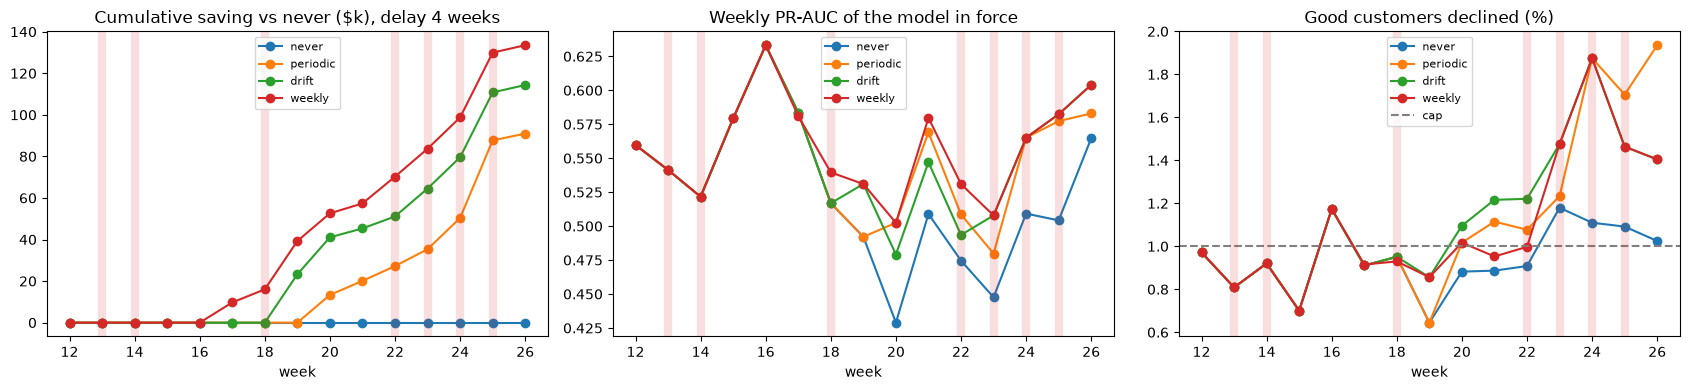

In [5]:
d, rule = 4, "bayes"
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for p in POLICIES:
    w = weekly[d, p, rule]
    axes[0].plot(w.index, (weekly[d, "never", rule]["cost"] - w["cost"]).cumsum() / 1e3, marker="o", label=p)
    axes[1].plot(w.index, w["pr_auc"], marker="o", label=p)
    axes[2].plot(w.index, w["good_customers_declined"] * 100, marker="o", label=p)
axes[0].set(title=f"Cumulative saving vs never ($k), delay {d} weeks", xlabel="week")
axes[1].set(title="Weekly PR-AUC of the model in force", xlabel="week")
axes[2].axhline(CAP * 100, color="gray", ls="--", label="cap")
axes[2].set(title="Good customers declined (%)", xlabel="week")
for ax in axes:
    for w in alarm_weeks:
        ax.axvline(w, color="C3", alpha=.15, lw=6)
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "bt_weekly.png", dpi=120, bbox_inches="tight")

## H3: do drift alarms precede performance drops?

The "never" model under a 4-week delay ages from 1 to 15 weeks. Its weekly PR-AUC is compared with the model retrained every week (the freshest possible): the gap is the cost of staleness. Shaded weeks had a drift alarm.

mean staleness gap in the week after an alarm vs after no alarm: 0.0389 vs 0.0315
correlation of model age with the never model's PR-AUC: -0.44


,model_age_never,pr_auc_never,pr_auc_fresh,staleness_gap,alarm,gap_next_week
week,,,,,,
12,1,0.5597,0.5597,0.0000,False,0.0000
13,2,0.5414,0.5414,0.0000,True,0.0000
14,3,0.5216,0.5216,0.0000,True,0.0000
15,4,0.5793,0.5793,0.0000,False,0.0000
16,5,0.6332,0.6332,0.0000,False,-0.0025
17,6,0.5836,0.5811,-0.0025,False,0.0227
18,7,0.5169,0.5396,0.0227,True,0.0389
19,8,0.4921,0.5310,0.0389,False,0.0735
20,9,0.4290,0.5025,0.0735,False,0.0708


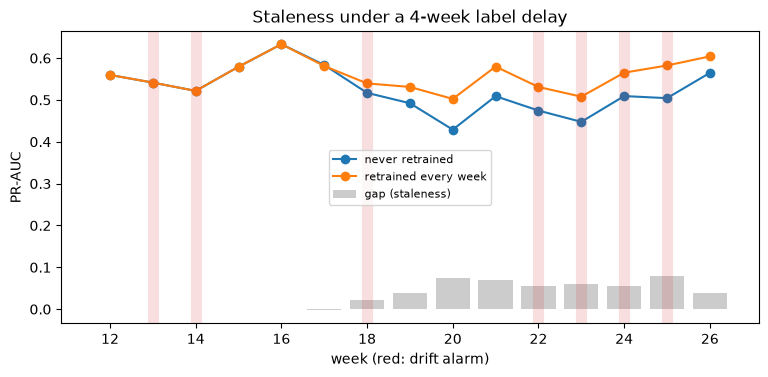

In [6]:
stale = weekly[4, "never", "bayes"]
fresh = weekly[4, "weekly", "bayes"]
h3 = pd.DataFrame({"model_age_never": stale["model_age"], "pr_auc_never": stale["pr_auc"], "pr_auc_fresh": fresh["pr_auc"],
                   "staleness_gap": fresh["pr_auc"] - stale["pr_auc"], "alarm": stale.index.isin(alarm_weeks)})
h3["gap_next_week"] = h3["staleness_gap"].shift(-1)
print("mean staleness gap in the week after an alarm vs after no alarm:",
      round(h3.loc[h3["alarm"], "gap_next_week"].mean(), 4), "vs", round(h3.loc[~h3["alarm"], "gap_next_week"].mean(), 4))
print("correlation of model age with the never model's PR-AUC:", round(np.corrcoef(h3["model_age_never"], h3["pr_auc_never"])[0, 1], 2))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(h3.index, h3["pr_auc_never"], marker="o", label="never retrained")
ax.plot(h3.index, h3["pr_auc_fresh"], marker="o", label="retrained every week")
ax.bar(h3.index, h3["staleness_gap"], color="gray", alpha=.4, label="gap (staleness)")
for w in alarm_weeks:
    ax.axvline(w, color="C3", alpha=.15, lw=8)
ax.set(xlabel="week (red: drift alarm)", ylabel="PR-AUC", title="Staleness under a 4-week label delay")
ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "bt_staleness.png", dpi=120, bbox_inches="tight")
h3.round(4)

In [7]:
# Sanity check against P2: cost of the never-retrained cost rule on test weeks 20-26.
print(f"never / bayes / delay 4, weeks 20-26: ${weekly[4, 'never', 'bayes'].loc[20:, 'cost'].sum():,.0f} "
      "(notebook 07, a different model trained on weeks 0-15: $378,609)")

never / bayes / delay 4, weeks 20-26: $466,593 (notebook 07, a different model trained on weeks 0-15: $378,609)
